# Прогнозування результатів шахових партій методами машинного навчання

Частина курсової роботи «Прогнозування результатів кіберспортивних змагань методами
машинного навчання» для платформи T-Forge. Порівнюються **два методи**:

1. **Логістична регресія** (мультиноміальна, зі стандартизацією ознак) — лінійна, пояснювана модель;
2. **Градієнтний бустинг дерев рішень** (`HistGradientBoostingClassifier`) — нелінійна модель, що враховує взаємодії ознак.

Обидва порівнюються з **базовою лінією Ело** — класичною формулою очікуваного результату з
постійною часткою нічиїх. Модель, яка не краща за Ело, не має сенсу в застосунку.

**Задача** — класифікація на три класи: перемога білих / нічия / перемога чорних.
Застосунок показує *ймовірності*, тому головні метрики — **log loss** і **Brier score**,
а не лише точність.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit

import train
from features import CLASS_ORDER, FEATURE_ORDER, TIME_CONTROLS

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

## 1. Дані

Датасет Kaggle «Chess Game Dataset (Lichess)» — ~20 тис. партій з Lichess.org. Для кожної
партії відомі рейтинги обох гравців, контроль часу, результат і час початку.

Фільтри: лише рейтингові партії (`rated`), без дублікатів за `id`, щонайменше 2 ходи.
Програш за часом лишається — це справжній результат.

*Примітка:* частина значень `created_at` у використаній копії файлу округлена до 6 значущих
цифр (≈ ±3 год) — файл пройшов через табличний редактор. Партії охоплюють кілька років, тож
упорядкування за часом це майже не порушує.

In [2]:
raw = pd.read_csv(train.DEFAULT_DATA)
df = train.load(train.DEFAULT_DATA)
print(f"Усього рядків: {len(raw)}, після фільтрів: {len(df)}")
df[["white_rating", "black_rating", "increment_code", "time_control", "winner"]].head()

Усього рядків: 20058, після фільтрів: 15461


,white_rating,black_rating,increment_code,time_control,winner
0,1500,1219,7+15,Rapid,white
1,1381,1575,10+20,Rapid,white
2,1348,1183,20+15,Classical,white
3,1398,1412,14+0,Rapid,white
4,1311,1320,5+8,Rapid,white


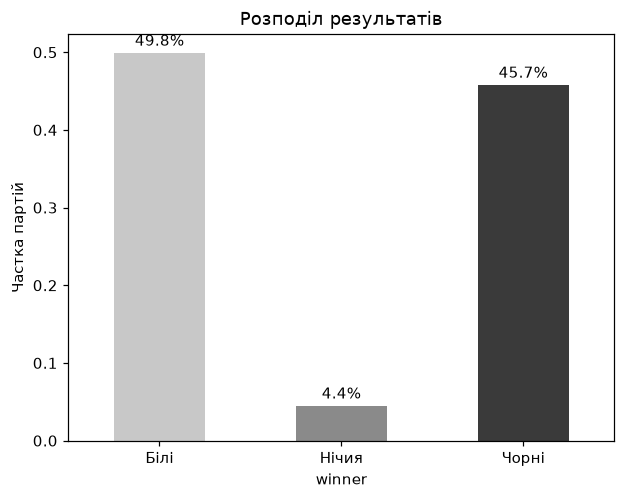

In [3]:
share = df["winner"].value_counts(normalize=True).reindex(CLASS_ORDER)
ax = share.rename({"white": "Білі", "draw": "Нічия", "black": "Чорні"}).plot.bar(color=["#c8c8c8", "#8a8a8a", "#3a3a3a"], rot=0)
ax.set_ylabel("Частка партій"); ax.set_title("Розподіл результатів")
for i, v in enumerate(share): ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.show()

Нічиїх у онлайн-шахах дуже мало (кілька відсотків). Це важливо для подальшого: модель, яка
обирає *найімовірніший* клас, майже ніколи не обере нічию — навіть якщо правильно оцінює її
ймовірність. Саме тому якість оцінюємо за ймовірнісними метриками.

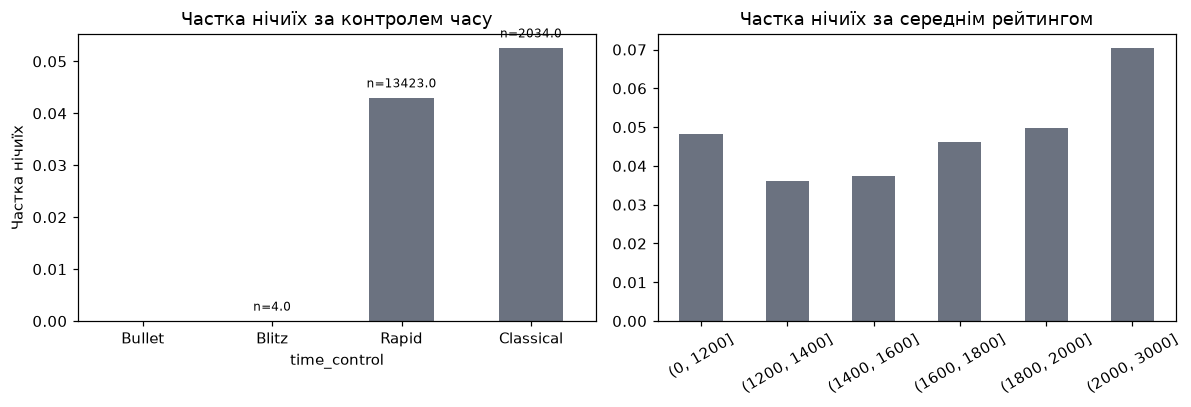

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_tc = df.groupby("time_control")["y"].apply(lambda s: (s == 1).mean()).reindex(TIME_CONTROLS)
by_tc.plot.bar(ax=axes[0], color="#6b7280", rot=0)
axes[0].set_title("Частка нічиїх за контролем часу"); axes[0].set_ylabel("Частка нічиїх")
counts = df["time_control"].value_counts().reindex(TIME_CONTROLS)
for i, (v, n) in enumerate(zip(by_tc, counts)): axes[0].text(i, v + 0.002, f"n={n}", ha="center", fontsize=8)

mean_rating = (df["white_rating"] + df["black_rating"]) / 2
bins = pd.cut(mean_rating, [0, 1200, 1400, 1600, 1800, 2000, 3000])
df.groupby(bins, observed=True)["y"].apply(lambda s: (s == 1).mean()).plot.bar(ax=axes[1], color="#6b7280", rot=30)
axes[1].set_title("Частка нічиїх за середнім рейтингом"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

Частка нічиїх зростає із середнім рейтингом гравців. Це залежність, яку лінійна модель може
вловити лише частково, — і саме тут градієнтний бустинг мав би шанс виграти.

**Важливе обмеження датасету:** майже всі партії — рапід і класика. Бліцу лише кілька партій,
куль (bullet) немає взагалі (див. `n=` на графіку). Прогноз для цих контролів — екстраполяція, і
застосунок позначає його як «мало даних». Виправити це може лише більший датасет — наприклад,
місячний дамп Lichess (`python train.py --data ...`).

## 2. Ознаки

Використовуються **лише ознаки, відомі до початку партії** і доступні в T-Forge:

| Ознака | Зміст |
|---|---|
| `rating_diff` | рейтинг білих − рейтинг чорних |
| `rating_mean` | середній рейтинг пари |
| `tc_bullet` … `tc_classical` | one-hot контролю часу |

Дебют, кількість ходів і спосіб завершення відомі лише *після* партії, тому до моделі не входять
(інакше це був би витік цільової змінної). Визначення ознак — у `features.py`; сервер T-Forge має
його точне дзеркало (`ChessFeatures.cs`), і тест паритету перевіряє, що обидва дають однакові ймовірності.

In [5]:
print(FEATURE_ORDER)
train.matrix(df.head(3))

['rating_diff', 'rating_mean', 'tc_bullet', 'tc_blitz', 'tc_rapid', 'tc_classical']


array([[ 2.8100e+02,  1.3595e+03,  0.0000e+00,  0.0000e+00,  1.0000e+00,
         0.0000e+00],
       [-1.9400e+02,  1.4780e+03,  0.0000e+00,  0.0000e+00,  1.0000e+00,
         0.0000e+00],
       [ 1.6500e+02,  1.2655e+03,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         1.0000e+00]], dtype=float32)

## 3. Розбиття за часом

Випадкове розбиття «підглядало» б у майбутнє: модель вчилася б на партіях, зіграних після тих,
які вона прогнозує. Тому старіші **80 %** партій — навчальна вибірка, новіші **20 %** — тестова.
Гіперпараметри підбираються крос-валідацією `TimeSeriesSplit` (5 фолдів) **лише на навчальній
частині**; тестова використовується один раз — для фінального порівняння.

In [6]:
train_df, test_df = train.split(df)
x_train, y_train = train.matrix(train_df), train_df["y"].to_numpy()
x_test, y_test = train.matrix(test_df), test_df["y"].to_numpy()
cv = TimeSeriesSplit(n_splits=5)
draw_rate = float((y_train == 1).mean())
print(f"Навчальна: {len(train_df)}, тестова: {len(test_df)}, частка нічиїх у навчальній: {draw_rate:.3%}")

Навчальна: 12368, тестова: 3093, частка нічиїх у навчальній: 4.310%


## 4. Метод 1 — логістична регресія

Мультиноміальна логістична регресія зі стандартизацією ознак. Підбирається сила регуляризації `C`.

In [7]:
logreg_search = train.fit_logreg(x_train, y_train, cv)
logreg = logreg_search.best_estimator_
print("Найкращий C:", logreg_search.best_params_)
coef = pd.DataFrame(logreg[-1].coef_, index=["Білі", "Нічия", "Чорні"], columns=FEATURE_ORDER)
coef

Найкращий C: {'logisticregression__C': 0.01}


,rating_diff,rating_mean,tc_bullet,tc_blitz,tc_rapid,tc_classical
Білі,0.4984,-0.0659,0.0,0.0281,0.0118,-0.0133
Нічия,-0.0367,0.1162,0.0,-0.0147,-0.0312,0.0320
Чорні,-0.4617,-0.0502,0.0,-0.0134,0.0194,-0.0187


Коефіцієнти — на стандартизованих ознаках, тож їх можна порівнювати між собою. Найбільший вплив має
`rating_diff`: додатний для перемоги білих і від'ємний для перемоги чорних — модель відтворює
логіку Ело.

## 5. Метод 2 — градієнтний бустинг

`HistGradientBoostingClassifier`. Підбираються темп навчання, глибина дерев і кількість ітерацій.
Перша сітка вибрала нижній кут за кожною віссю, тому її розширено вниз (див. `train.py`).

Найкращі параметри: {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 50}


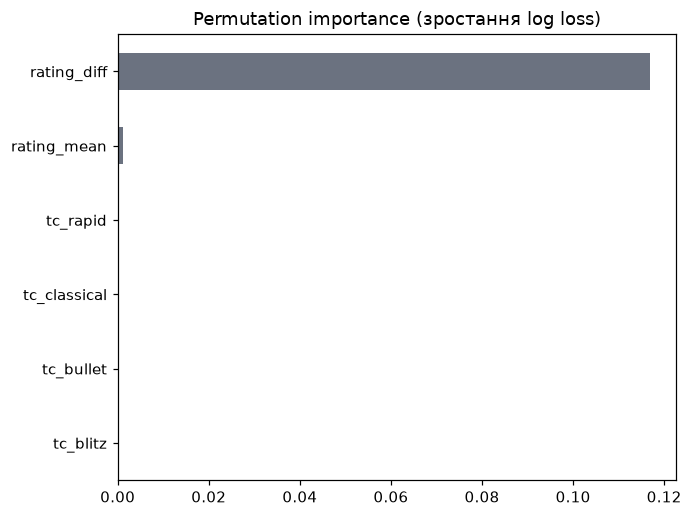

In [8]:
gbt_search = train.fit_gbt(x_train, y_train, cv)
gbt = gbt_search.best_estimator_
print("Найкращі параметри:", gbt_search.best_params_)
imp = permutation_importance(gbt, x_test, y_test, scoring="neg_log_loss", n_repeats=10, random_state=42)
importance = pd.Series(imp.importances_mean, index=FEATURE_ORDER).sort_values()
ax = importance.plot.barh(color="#6b7280")
ax.set_title("Permutation importance (зростання log loss)"); plt.tight_layout()
plt.savefig(train.OUT / "importance.png"); plt.show()

Бустинг обрав найпростішу конфігурацію з сітки (неглибокі дерева, мало ітерацій). Це означає, що
в цих трьох ознаках мало нелінійної структури, якої не бачить лінійна модель: складніші дерева лише
перенавчаються. Майже вся інформація — у різниці рейтингів.

## 6. Порівняння

In [9]:
probs = {
    "Логістична регресія": logreg.predict_proba(x_test),
    "Градієнтний бустинг": gbt.predict_proba(x_test),
    "Ело (базова лінія)": train.elo_probs(test_df, draw_rate),
}
results = pd.DataFrame({name: train.evaluate(y_test, p) for name, p in probs.items()}).T
results.columns = ["Log loss ↓", "Brier ↓", "Точність ↑", "Recall нічиїх ↑"]
results

,Log loss ↓,Brier ↓,Точність ↑,Recall нічиїх ↑
Логістична регресія,0.7865,0.4850,0.6101,0.0
Градієнтний бустинг,0.7889,0.4871,0.6056,0.0
Ело (базова лінія),0.8127,0.4852,0.6052,0.0


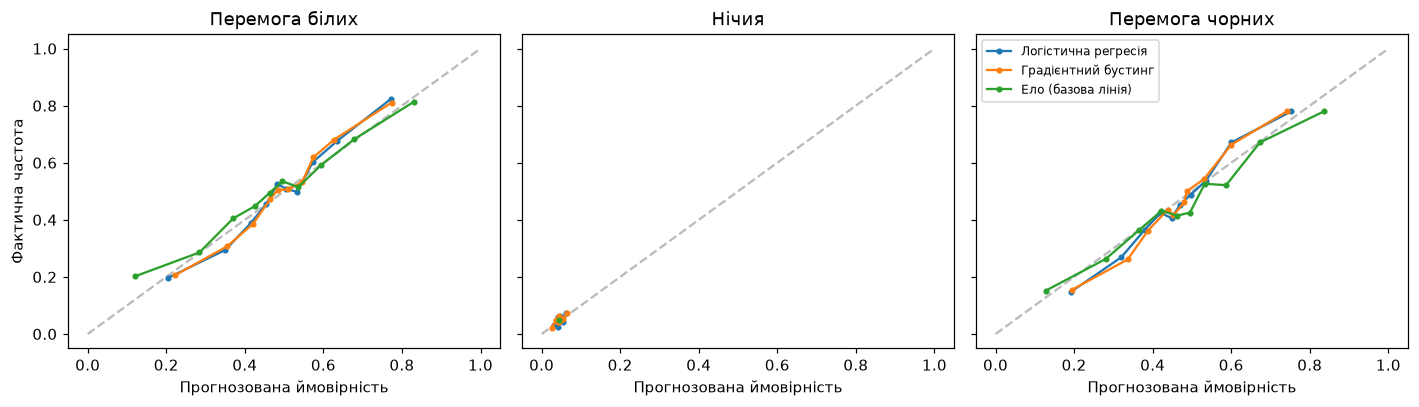

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for k, label in enumerate(["Перемога білих", "Нічия", "Перемога чорних"]):
    ax = axes[k]
    ax.plot([0, 1], [0, 1], ls="--", color="#bbb")
    for name, p in probs.items():
        frac, mean = calibration_curve(y_test == k, p[:, k], n_bins=10, strategy="quantile")
        ax.plot(mean, frac, marker="o", ms=3, label=name)
    ax.set_title(label); ax.set_xlabel("Прогнозована ймовірність")
axes[0].set_ylabel("Фактична частота"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(train.OUT / "calibration.png"); plt.show()

In [11]:
diff = probs["Градієнтний бустинг"][:, 1] - probs["Логістична регресія"][:, 1]
print("Середня P(нічия), факт:", f"{(y_test == 1).mean():.4f}")
for name, p in probs.items():
    print(f"  {name:22s} середня P(нічия) = {p[:, 1].mean():.4f}, макс = {p[:, 1].max():.4f}")

Середня P(нічия), факт: 0.0488
  Логістична регресія    середня P(нічия) = 0.0460, макс = 0.0912
  Градієнтний бустинг    середня P(нічия) = 0.0450, макс = 0.1111
  Ело (базова лінія)     середня P(нічия) = 0.0431, макс = 0.0431


## 7. Висновки

1. **Обидва методи кращі за базову лінію Ело за log loss** — головною метрикою, бо застосунок
   показує ймовірності. Отже, модель додає інформацію понад саму формулу Ело: перевагу білих,
   залежність нічиїх від рівня гравців і контролю часу.
2. **Логістична регресія не поступається градієнтному бустингу**, а за log loss і Brier трохи
   переважає його. На трьох ознаках, де майже вся інформація — у різниці рейтингів, складніша
   модель не має що вивчити й лише ризикує перенавчитися.
3. **Recall нічиїх дорівнює нулю для всіх методів.** Нічиїх кілька відсотків, тож нічия ніколи не
   буває найімовірнішим результатом. Це не вада моделей, а властивість даних; правильна оцінка —
   ймовірнісна (калібрування на графіку вище). Гіпотезу, що бустинг виграє саме на нічиїх, на цих
   даних **не підтверджено**.
4. **Точність близько 60 %** у всіх трьох — межа, яку задають самі ознаки.
5. **За Brier score переваги майже немає**: логістична регресія лише на соті частки краща за Ело,
   а бустинг трохи гірший. Виграш моделей — передусім у log loss, тобто в тому, що вони рідше дають
   упевнено хибні ймовірності.
6. **Контроль часу майже не впливає** на прогноз — але лише тому, що в даних немає ні куль, ні
   бліцу; про ці контролі датасет нічого не каже.

**Обмеження.** Онлайн-рейтинг Lichess — не рейтинг FIDE, і гравці T-Forge вказують свій рейтинг
самі. Немає ознак форми гравця чи історії особистих зустрічей: у T-Forge командний матч зберігає
лише рахунок, а не результати окремих дощок, тож такі ознаки неможливо порахувати на боці
застосунку. Наступний крок — більший датасет (місячний дамп Lichess, `python train.py --data ...`)
і ознаки з історії партій, коли T-Forge почне її зберігати.

**У застосунку** обидві моделі експортовано в ONNX і показано поруч із базовою лінією Ело на
сторінках шахових дуелей і командних матчів.